<a href="https://colab.research.google.com/github/m34373753-netizen/hello-wor/blob/main/Welcome_To_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [106]:
from google.colab import ai
response = ai.generate_text("What is the capital of France?")

In [107]:
seconds_in_a_day = 24 * 60 * 60
seconds_in_a_day

86400

To execute the code in the above cell, select it with a click and then either press the play button to the left of the code, or use the keyboard shortcut "Command/Ctrl+Enter". To edit the code, just click the cell and start editing.

Variables that you define in one cell can later be used in other cells:

In [108]:
seconds_in_a_week = 7 * seconds_in_a_day
seconds_in_a_week

604800

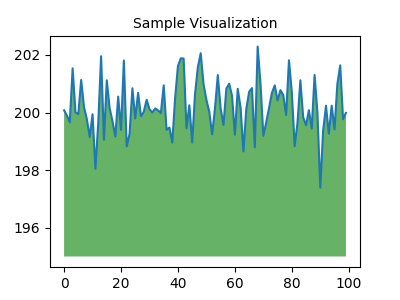

In [109]:
import numpy as np
import IPython.display as display
from matplotlib import pyplot as plt
import io
import base64

ys = 200 + np.random.randn(100)
x = [x for x in range(len(ys))]

fig = plt.figure(figsize=(4, 3), facecolor='w')
plt.plot(x, ys, '-')
plt.fill_between(x, ys, 195, where=(ys > 195), facecolor='g', alpha=0.6)
plt.title("Sample Visualization", fontsize=10)

data = io.BytesIO()
plt.savefig(data)
image = F"data:image/png;base64,{base64.b64encode(data.getvalue()).decode()}"
alt = "Sample Visualization"
display.display(display.Markdown(F"""![{alt}]({image})"""))
plt.close(fig)

Linear Regression
========
Linear regression is the simplest of all machine learning models. It tries to approximate the pattern of the given data into a straight line.

Let us optimize a linear model using the Gradient Descent algorithm.


<img src="https://cdn-images-1.medium.com/max/800/1*KwdVLH5e_P9h8hEzeIPnTg.png"  width = 300px>

In [110]:
import matplotlib.pyplot as plt
import numpy as np


Now we generate artificial data. Do not worry about this part.

Let us assume that we are given the dataset:

      x_sample = Distance of Uber Ride
      y_sample = Corresponding Cost
    
    

In [111]:
# Linear Regression

# Generating artificial dataset
x_sample = np.linspace(1,15,100)
noise1 = np.random.uniform(-0.3,0.3, size=(100))
noise2 = np.random.uniform(-20,20, size=(100))
y_sample = 4*x_sample + 200
y_sample = y_sample + noise2
x_sample = x_sample + noise1




We want to approximate this data into a linear function.

Let us assume :

    y = mx + c
    
as the function.

Here m is the slope of the line, and c is the y intercept.


Here comes the important part.

IMPORTANT
========

for all those who planned to scroll without paying attention!


We define our algorithm's performance here. We model our loss function as the mean squared error between the predicted values and the dataset

<img src="https://cdn-images-1.medium.com/max/800/1*AQKoBlrYPA6kjvW8XomKUQ.png"  width= 300px>

(read the b as c or whatever!)

In [112]:
def linear_function(m,c,x):
  return m*x+c



The Error is a function of both m and c. We would like to get that error minimized.

How?

Method 1: Take the partial derrivatives with respect to m and c, and equate them to zero. Take 2nd order derrivatives and verify that it is a minima.
Drawbacks of this method, this is not scalable to large datasets.

Method 2: Take the derrivatives and move in the direction where error decreases maximum. Do this a lot of times, till you become the happiest person in the world and error does not change much.

<img src ="https://cdn-images-1.medium.com/max/800/1*3YJx2rdqMW5ccRJZFH9v6w.png" width=300 >



In [113]:
def derrivative_of_error_m(m,c,x_sample,y_sample):
  derrivative = -2*np.sum((y_sample - linear_function(m,c,x_sample))*x_sample)
  return derrivative/len(x_sample)

def derrivative_of_error_c(m,c,x_sample,y_sample):
  derrivative = -2 * np.sum((y_sample - linear_function(m,c,x_sample)))
  return derrivative/len(x_sample)

We create an optimizer object. If you are not familiar with Classes, you can do the same thing without classes. We basically run a while loop inside till the error becomes lower than the given threshold. We also put a condition to the number of iterations so that the loop breaks if we are not converging.


Notice the parameter Learning Rate.

Learning rate is crucial for the convergence of the algorithm.
Low learning rate can make it take a long time to converge. A high learning rate can cause the parameters to be optimised to oscilate near the minima or even diverge.

<img src="https://www.jeremyjordan.me/content/images/2018/02/Screen-Shot-2018-02-24-at-11.47.09-AM.png" width = 500px>




In [114]:
class GradientDescent():
  def __init__(self,m,c, learning_rate):
    self.m = 0
    self.c = 0
    self.error = 10000
    self.learning_rate = learning_rate
    # logging stuffs, don't worry
    self.error_log = []
    self.m_log = []
    self.c_log = []
    self.dm_log = []
    self.dc_log = []
  def optimize(self, x_sample,y_sample, threshold = 10):
    num_iter = 0
    while(self.error> threshold and num_iter <10000):
      num_iter = num_iter+1
      self.error = error(self.m, self.c, x_sample, y_sample)
      dm = self.learning_rate*(derrivative_of_error_m(self.m, self.c, x_sample, y_sample))
      dc = self.learning_rate*(derrivative_of_error_c(self.m, self.c, x_sample, y_sample))
      self.m = self.m - dm
      self.c = self.c - dc

      #logging
      self.m_log.append(self.m)
      self.c_log.append(self.c)
      self.dm_log.append(dm)
      self.dc_log.append(dc)
      self.error_log.append(self.error)

      print("Current Loss:\t %f" %self.error)
      print("Current Value:\n\tm:\t%f\n\tc:\t%f" %(self.m,self.c))
      print("_"*100)

In [115]:
initial_m = 0
initial_c = 0
learning_rate = 0.01
alg = GradientDescent(initial_m,initial_c,learning_rate)
alg.optimize(x_sample,y_sample,200)


Current Loss:	 53795.927939
Current Value:
	m:	38.390964
	c:	4.620532
____________________________________________________________________________________________________
Current Loss:	 26298.655453
Current Value:
	m:	13.963742
	c:	3.000508
____________________________________________________________________________________________________
Current Loss:	 15246.004008
Current Value:
	m:	29.294803
	c:	5.324798
____________________________________________________________________________________________________
Current Loss:	 10780.802824
Current Value:
	m:	19.463297
	c:	5.147399
____________________________________________________________________________________________________
Current Loss:	 8954.612914
Current Value:
	m:	25.557756
	c:	6.548022
____________________________________________________________________________________________________
Current Loss:	 8185.825751
Current Value:
	m:	21.573165
	c:	6.944630
_____________________________________________________________________________

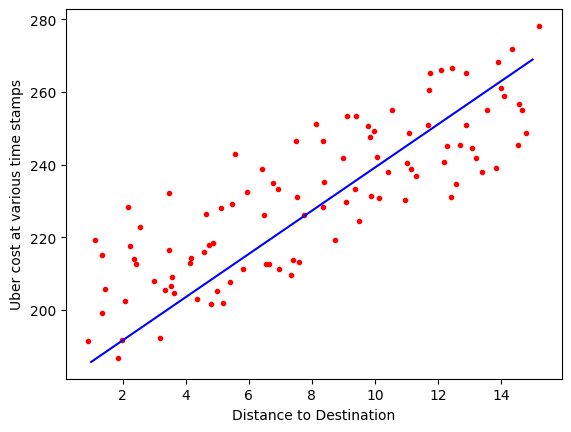

In [116]:
plt.xlabel("Distance to Destination")
plt.ylabel("Uber cost at various time stamps")
plt.plot(x_sample,y_sample, ".r")


x = np.linspace(1,15,100)
y = linear_function(alg.m,alg.c,x)
plt.plot(x,y,"-b")

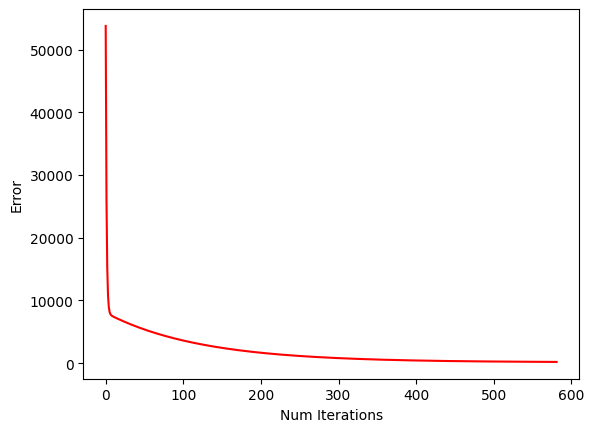

In [117]:
plt.xlabel("Num Iterations")
plt.ylabel("Error")
plt.plot(alg.error_log, 'r-')

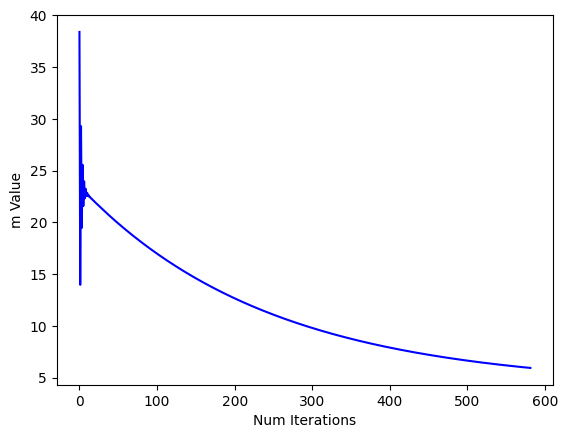

In [118]:
plt.xlabel("Num Iterations")
plt.ylabel("m Value")
plt.plot(alg.m_log, 'b-')

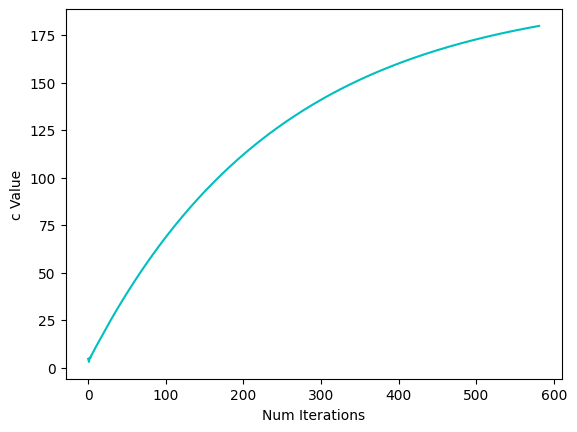

In [119]:
plt.xlabel("Num Iterations")
plt.ylabel("c Value")
plt.plot(alg.c_log, 'c-')

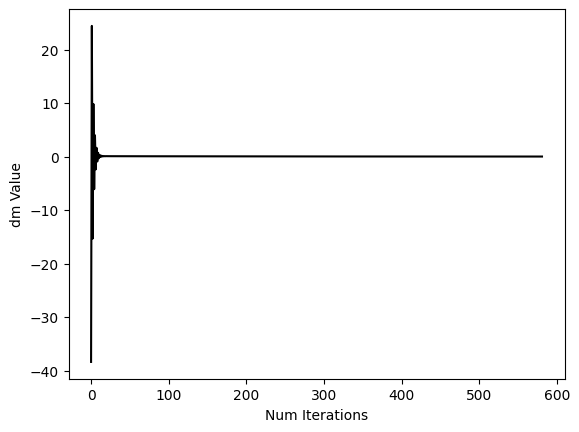

In [120]:
plt.xlabel("Num Iterations")
plt.ylabel("dm Value")
plt.plot(alg.dm_log, 'k-')

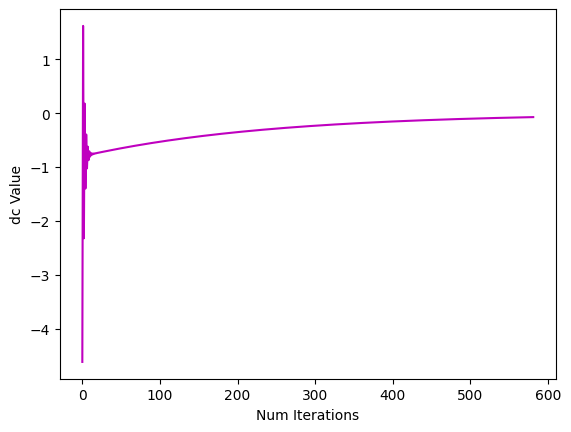

In [121]:
plt.xlabel("Num Iterations")
plt.ylabel("dc Value")
plt.plot(alg.dc_log, 'm-')